# K-Means 2일차 — 군집 결과 확인 · SSE · 엘보우 · 실루엣

수업 필기 `비지도학습_K_Means` (2일차 부분)와 메모 `2일_비지도학습_K_Means.txt` 를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v7 p.128~133 — 16. 비지도 학습)

- 1일차(K-Means 원리 · 직접 구현 · k=2/3)는 [Day 027 `kmeans_clustering.ipynb`](../../2026-10-16/lecture/kmeans_clustering.ipynb) 에 정리했습니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.
- 같은 날 배운 교차 검증 · `GridSearchCV` 는 [`cross_validation_gridsearch.ipynb`](./cross_validation_gridsearch.ipynb)(분류), [`gridsearch_regression.ipynb`](./gridsearch_regression.ipynb)(회귀) 에 있습니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 복습 — 군집화와 K-Means (교재 p.129~131)

| | 분류 (지도 학습) | 군집화 (비지도 학습) |
|---|---|---|
| 정답(레이블) | 있음 | **없음** |
| 하는 일 | 미지의 데이터의 범주를 **예측** | 비슷한 데이터끼리 스스로 **그룹(클러스터)** 으로 묶기 |

좋은 군집 = **군집 간 분산은 최대**(그룹끼리 멀리) + **군집 내 분산은 최소**(그룹 안은 촘촘히).

K-Means : 중심점 k 개 → ① 각 점을 **유클리드 거리**가 가장 가까운 중심점에 할당 → ② 중심점을 그 점들의 **좌표 평균**으로 이동 → 중심점이 움직이지 않을 때까지 반복.

In [2]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./iris_dataset.csv')

# 군집화에 사용할 데이터 : 꽃잎 길이, 꽃잎 너비 (정답 label 은 넣지 않는다)
wl_data = df[['petal length (cm)', 'petal width (cm)']]
print(df.shape, '->', wl_data.shape)
df['label'].value_counts()

(150, 5) -> (150, 2)


label
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

> **📝 고친 부분** — 경로 `C:\\Users\\...\\iris_dataset.csv` → 노트북과 같은 폴더 `./iris_dataset.csv`, 쓰지 않는 `#from sklearn.cluster import k_means` · `#w_data = ...` 정리

## 2. 군집 결과 확인 — 군집별 데이터 수 (`np.unique`)

군집화에는 정답을 쓰지 않았지만, **확인할 때는** 정답과 비교해 볼 수 있다.
`np.unique(배열, return_counts=True)` → **(항목, 항목별 개수)** 튜플.

In [3]:
# k = 2
model1 = KMeans(n_clusters=2, random_state=0)
output1 = model1.fit_predict(wl_data)        # 학습 + 각 데이터의 군집 번호
print(output1)

# 필기 그대로 : 0~49번(setosa) / 50~149번(versicolor + virginica) 구간의 군집 번호 세기
print("=" * 50)
print("0~49번   :", np.unique(output1[0:50], return_counts=True))
print("50~149번 :", np.unique(output1[50:], return_counts=True))

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]
0~49번   : (array([1], dtype=int32), array([50]))
50~149번 : (array([0, 1], dtype=int32), array([99,  1]))


setosa 50송이는 전부 1번 군집, 나머지 100송이 중 **99송이는 0번, 1송이만 1번** — 꽃잎이 가장 작은 versicolor 1송이가 setosa 쪽으로 갔다.

필기처럼 **인덱스 구간으로 자르는 방법은 데이터가 품종별로 정렬돼 있을 때만** 맞는다. 정렬 여부와 상관없이 쓰려면 **정답별로 묶어서** 센다.

In [4]:
# 정렬 상태에 의존하지 않는 방법 1 : 정답(label)별로 군집 번호 세기
for name, group in pd.Series(output1).groupby(df['label']):
    items, counts = np.unique(group, return_counts=True)
    print(f"{name:<11} : 군집 {items.tolist()} -> {counts.tolist()}송이")

# 방법 2 : 교차표 한 번에
pd.crosstab(df['label'], output1, rownames=['정답 품종'], colnames=['군집 (k=2)'])

setosa      : 군집 [1] -> [50]송이
versicolor  : 군집 [0, 1] -> [49, 1]송이
virginica   : 군집 [0] -> [50]송이


군집 (k=2),0,1
정답 품종,,
setosa,0,50
versicolor,49,1
virginica,50,0


In [5]:
# k = 3
model2 = KMeans(n_clusters=3, random_state=0)
output2 = model2.fit_predict(wl_data)

print("군집 전체 :", np.unique(output2, return_counts=True))
print("=" * 50)
for name, group in pd.Series(output2).groupby(df['label']):
    items, counts = np.unique(group, return_counts=True)
    print(f"{name:<11} : 군집 {items.tolist()} -> {counts.tolist()}송이")

pd.crosstab(df['label'], output2, rownames=['정답 품종'], colnames=['군집 (k=3)'])

군집 전체 : (array([0, 1, 2], dtype=int32), array([52, 50, 48]))
setosa      : 군집 [1] -> [50]송이
versicolor  : 군집 [0, 2] -> [48, 2]송이
virginica   : 군집 [0, 2] -> [4, 46]송이


군집 (k=3),0,1,2
정답 품종,,,
setosa,0,50,0
versicolor,48,0,2
virginica,4,0,46


In [6]:
# 각 군집에서 가장 많은 품종을 그 군집의 이름으로 정하면 → 정답과 몇 송이가 일치?
mapping = pd.crosstab(output2, df['label']).idxmax(axis=1)
print("군집 번호 → 품종 :", mapping.to_dict())
match = (pd.Series(output2).map(mapping) == df['label'])
print(f"일치 : {match.sum()} / 150 송이 ({match.mean():.0%})")
print("어긋난 데이터 :")
df[~match]

군집 번호 → 품종 : {0: 'versicolor', 1: 'setosa', 2: 'virginica'}
일치 : 144 / 150 송이 (96%)
어긋난 데이터 :


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
77,6.7,3.0,5.0,1.7,versicolor
83,6.0,2.7,5.1,1.6,versicolor
106,4.9,2.5,4.5,1.7,virginica
119,6.0,2.2,5.0,1.5,virginica
126,6.2,2.8,4.8,1.8,virginica
138,6.0,3.0,4.8,1.8,virginica


| 정답 품종 | 군집 1 | 군집 0 | 군집 2 |
|---|---|---|---|
| setosa | **50** | 0 | 0 |
| versicolor | 0 | **48** | 2 |
| virginica | 0 | 4 | **46** |

versicolor 와 virginica 의 **경계에 있는 6송이**만 어긋났다(96%). 꽃잎 크기만으로는 두 품종이 일부 겹치기 때문.

> **📝 고친 부분** (`비지도학습_K_Means`)
> - 제목 `군집화(n_clusters='3',PC3)` → `n_clusters` 는 **정수 `3`** (문자열 `'3'` 이 아니다). **PC3 는 PCA 의 세 번째 주성분**이라 K-Means 와 관계없다 — 여기서는 "군집 3개".
> - 출력 이름 `pc2.군집화` · `pc2-3.군집화` → 각 구간은 PC 가 아니라 **품종(setosa · versicolor · virginica)** 이다. 또 필기에 저장된 출력(`pc3.군집화`)과 코드의 문자열(`pc2-3.군집화`)이 달랐다 — 코드를 고친 뒤 다시 실행하지 않은 것.
> - 메모 "거리 기반 **평균**으로 경계선(기준선)을 만든다" → K-Means 는 경계선을 직접 만들지 않는다. **중심점(좌표 평균)** 을 정하고, 각 점이 **가장 가까운 중심점**에 속하면 결과적으로 두 중심점의 **수직 이등분선**이 경계가 된다.

## 3. SSE(오차제곱합) = `inertia_` (교재 p.132)

**SSE** = 각 데이터에서 **자기 군집의 중심점까지 거리**를 제곱해서 모두 더한 값.

$$SSE = \sum_{i=1}^{n} \lVert x_i - c_{\text{자기 군집}} \rVert^2$$

작을수록 군집 안이 촘촘하다(= 군집 내 분산 최소). sklearn 에서는 `model.inertia_`.

In [7]:
# 직접 계산해서 inertia_ 와 비교
centers = model2.cluster_centers_[output2]           # 각 데이터가 속한 군집의 중심점 좌표
sse = ((wl_data.to_numpy() - centers) ** 2).sum()

print("직접 계산한 SSE :", round(sse, 4))
print("model.inertia_  :", round(model2.inertia_, 4))
print("평균 (SSE / n)   :", round(model2.inertia_ / len(wl_data), 4), " ← 데이터 1개당 중심점까지 거리 제곱의 평균")

직접 계산한 SSE : 31.3714
model.inertia_  : 31.3714
평균 (SSE / n)   : 0.2091  ← 데이터 1개당 중심점까지 거리 제곱의 평균


> **📝 고친 부분** (메모 · 주석)
> - "SSE : 중심점 데이터, 주변에 있는 오차 거리차 제곱 합계" → **각 데이터 ↔ 자기 군집 중심점** 거리의 제곱 합.
> - 주석 "SSE 보다 MSE(혹은 RMSE)를 더 자주 사용" → 그건 **회귀 모델 평가** 이야기. K-Means 는 정의 자체가 **SSE 를 최소화**하는 알고리즘이고, 엘보우에서는 **같은 데이터(같은 n)** 로 k 만 바꿔 비교하므로 SSE 든 SSE/n 이든 **곡선 모양이 똑같다**.

## 4. 엘보우(elbow) — 최적의 k (교재 p.132)

k 를 1 → 10 으로 늘리면 SSE 는 **항상 줄어든다**(k = 150 이면 점마다 중심점 → SSE 0). 그래서 "SSE 가 가장 작은 k" 가 아니라, **크게 줄다가 완만해지는 꺾이는 지점(팔꿈치)** 을 고른다.

k= 1 : SSE =  550.90
k= 2 : SSE =   86.39  (84% 감소)
k= 3 : SSE =   31.37  (64% 감소)
k= 4 : SSE =   19.48  (38% 감소)
k= 5 : SSE =   14.13  (27% 감소)
k= 6 : SSE =   11.83  (16% 감소)
k= 7 : SSE =    9.83  (17% 감소)
k= 8 : SSE =    8.04  (18% 감소)
k= 9 : SSE =    6.76  (16% 감소)
k=10 : SSE =    6.38  (6% 감소)


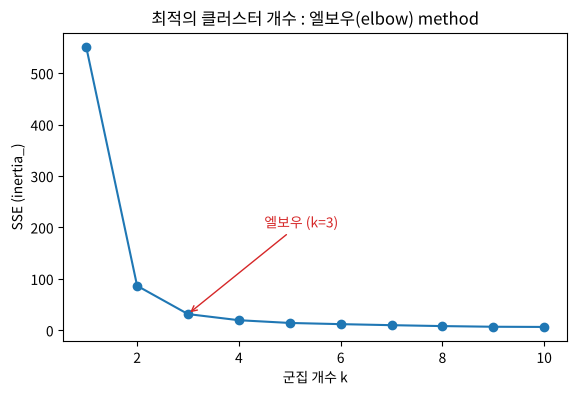

In [8]:
sse_list = []
clusters = range(1, 11)
for k in clusters:
    model = KMeans(n_clusters=k, random_state=0)
    model.fit(wl_data)                 # SSE 만 필요하면 fit 으로 충분
    sse_list.append(model.inertia_)

for k, s in zip(clusters, sse_list):
    drop = '' if k == 1 else f"  ({(sse_list[k - 2] - s) / sse_list[k - 2]:.0%} 감소)"
    print(f"k={k:>2} : SSE = {s:7.2f}{drop}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(list(clusters), sse_list, marker='o')
ax.annotate('엘보우 (k=3)', xy=(3, sse_list[2]), xytext=(4.5, 200),
            arrowprops=dict(arrowstyle='->', color='tab:red'), color='tab:red')
ax.set_xlabel('군집 개수 k'); ax.set_ylabel('SSE (inertia_)')
ax.set_title('최적의 클러스터 개수 : 엘보우(elbow) method')
plt.show()

k = 1 → 2 에서 **84%**, 2 → 3 에서 **64%** 줄다가 3 → 4 부터는 38%, 27% … 로 완만해진다 → **k = 3**.

> **📝 고친 부분**
> - 필기의 엘보우 그래프는 `plotly` 라 GitHub 미리보기에서 보이지 않는다 → matplotlib 로 다시 그렸다.
> - 메모 "SSE 의 변화가 **가장 크게** 감소하는 구간 → 최적의 개수"(교재 p.132 그대로) → 가장 크게 줄어드는 구간은 항상 k = 1 → 2 다. 정확히는 **크게 줄다가 완만해지기 시작하는 지점**(감소폭이 급격히 작아지는 곳).
> - "군집화 끝나면 → **군집별** SSE 를 제공한다" → `inertia_` 는 **모든 군집을 합친** SSE 하나다. 군집별로 보려면 직접 나눠 계산한다(아래).

In [9]:
# 군집별 SSE — inertia_ 는 이것들의 합
per_cluster = pd.Series(((wl_data.to_numpy() - centers) ** 2).sum(axis=1)).groupby(output2).sum()
print(per_cluster.round(2).to_dict(), "→ 합계", round(per_cluster.sum(), 2))

{0: 13.06, 1: 2.02, 2: 16.29} → 합계 31.37


## 5. 엘보우가 애매할 때 — 실루엣 계수(silhouette)

각 데이터마다
- **a** = 같은 군집 안의 다른 점들까지 평균 거리 (작을수록 좋음)
- **b** = 가장 가까운 **다른** 군집의 점들까지 평균 거리 (클수록 좋음)
- **실루엣 = (b − a) / max(a, b)** → **1 에 가까우면 잘 묶임**, 0 근처면 경계, 음수면 잘못 묶임

모든 데이터의 평균이 `silhouette_score`. SSE 와 달리 k 가 커진다고 무조건 좋아지지 않는다.

In [10]:
from sklearn.metrics import silhouette_score, silhouette_samples

for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=0).fit_predict(wl_data)
    print(f"k={k} : 실루엣 = {silhouette_score(wl_data, labels):.3f}")

k=2 : 실루엣 = 0.765
k=3 : 실루엣 = 0.660


k=4 : 실루엣 = 0.611
k=5 : 실루엣 = 0.589
k=6 : 실루엣 = 0.572


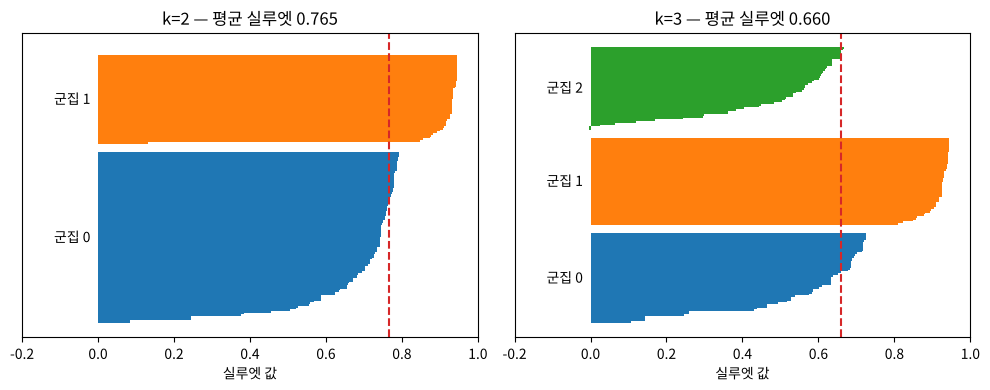

In [11]:
# k = 2 와 k = 3 의 실루엣 막대 (데이터 하나하나의 실루엣 값)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, k in zip(axes, [2, 3]):
    labels = KMeans(n_clusters=k, random_state=0).fit_predict(wl_data)
    s = silhouette_samples(wl_data, labels)
    y0 = 0
    for c in range(k):
        vals = np.sort(s[labels == c])
        ax.barh(range(y0, y0 + len(vals)), vals, height=1.0)
        ax.text(-0.02, y0 + len(vals) / 2, f'군집 {c}', ha='right', va='center')
        y0 += len(vals) + 5
    ax.axvline(s.mean(), color='tab:red', ls='--')
    ax.set_title(f'k={k} — 평균 실루엣 {s.mean():.3f}')
    ax.set_xlabel('실루엣 값'); ax.set_xlim(-0.2, 1)
axes[0].set_yticks([])
plt.tight_layout()
plt.show()

![실루엣 애니메이션](./images/anim_05_silhouette.gif)

🎬 k 를 2 → 6 으로 바꾸며 왼쪽은 군집 결과, 오른쪽은 데이터별 실루엣 막대. **k = 2 (0.765)** 가 가장 높다 — setosa 와 나머지는 **아주 확실히** 갈라지기 때문. k = 3 (0.660)은 versicolor · virginica 가 맞닿아 있어 경계의 점들 실루엣이 낮다.

| k | SSE | 실루엣 |
|---|---|---|
| 2 | 86.39 | **0.765** |
| 3 | 31.37 (엘보우) | 0.660 |
| 4 | 19.48 | 0.611 |

- 엘보우는 k = 3, 실루엣은 k = 2 → **지표가 서로 다른 답**을 줄 수 있다. 지표는 참고이고, **도메인 지식**(붓꽃은 3품종)과 **군집을 어디에 쓸지**로 최종 결정한다.
- 이것이 [Day 027](../../2026-10-16/) 복습에 남겨 둔 질문("엘보우가 뚜렷하지 않을 때")에 대한 답.